# PrediCare TPA — Exploration, features et contrôle RGPD 



## 0. Configuration

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.privacy import (COLONNES_SANTE, COLONNES_QUASI_IDENTIFIANTS,
                         verifier_sans_pii, verifier_features_ml)

RAW = Path("../data/raw/dataset")
LABELS = Path("../data/raw/labels")
PROCESSED = Path("../data/processed")
REPORTS = Path("../reports")
PROCESSED.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)
FUITE = ["statut", "motif_rejet", "montant_pris_en_charge", "date_traitement", "reste_a_charge"]

sns.set_theme(style="whitegrid")


def sauver(nom):
    plt.tight_layout()
    plt.savefig(REPORTS / f"{nom}.png", dpi=120)
    plt.show()

## 1. Chargement et séparation des colonnes de fuite

In [2]:
t = {f.stem: pd.read_csv(f) for f in RAW.glob("*.csv") if f.stem != "identites_pii"}

for nom, df in t.items():
    print(f"{nom:25s} {df.shape}")

assures                   (4459, 9)
contrats                  (1500, 12)
factures                  (84593, 24)
garanties                 (27, 11)
grille_tarifaire          (3242, 3)
lignes_facture            (123270, 9)
ordonnances               (47804, 8)
ordonnance_lignes         (82175, 6)
prestataires              (251, 20)
referentiel_actes         (58, 12)
referentiel_medicaments   (28, 6)


In [3]:

decisions = t["factures"][["facture_id"] + FUITE].copy()
decisions["date_traitement"] = pd.to_datetime(decisions["date_traitement"])
t["factures"] = t["factures"].drop(columns=FUITE)

print("Factures :", t["factures"].shape, "| colonnes de fuite retirées :", FUITE)
assert not set(FUITE) & set(t["factures"].columns)

Factures : (84593, 19) | colonnes de fuite retirées : ['statut', 'motif_rejet', 'montant_pris_en_charge', 'date_traitement', 'reste_a_charge']


## 2. Qualité des données

In [4]:
for nom, df in t.items():
    print("=" * 50)
    print(nom, df.shape)
    manquants = df.isna().sum()
    print("Valeurs manquantes :")
    print(manquants[manquants > 0] if manquants.sum() > 0 else "aucune")
    print("Lignes dupliquées :", df.duplicated().sum())

assures (4459, 9)
Valeurs manquantes :
date_radiation    4130
dtype: int64
Lignes dupliquées : 0
contrats (1500, 12)
Valeurs manquantes :
date_fin    1391
dtype: int64
Lignes dupliquées : 0
factures (84593, 19)
Valeurs manquantes :
ordonnance_id           37688
attestation_pec_id      67603
entente_prealable_id    84265
dtype: int64
Lignes dupliquées : 0
garanties (27, 11)
Valeurs manquantes :
actes_exclus    9
dtype: int64
Lignes dupliquées : 0
grille_tarifaire (3242, 3)
Valeurs manquantes :
aucune
Lignes dupliquées : 0
lignes_facture (123270, 9)
Valeurs manquantes :
aucune
Lignes dupliquées : 0
ordonnances (47804, 8)
Valeurs manquantes :
diagnostic                191
renseignement_clinique    191
dtype: int64
Lignes dupliquées : 0
ordonnance_lignes (82175, 6)
Valeurs manquantes :
posologie    6793
dtype: int64
Lignes dupliquées : 0
prestataires (251, 20)
Valeurs manquantes :
specialite             209
numero_onm             136
date_fin_convention    242
dtype: int64
Lignes dupliquée

In [5]:
colonnes_dates = {
    "factures": ["date_soin", "date_facture", "date_reception"],
    "ordonnances": ["date_prescription"],
    "assures": ["date_adhesion", "date_radiation"],
    "contrats": ["date_effet_police", "date_effet", "date_fin"],
    "prestataires": ["date_conventionnement", "date_fin_convention"],
}
for nom, cols in colonnes_dates.items():
    for c in cols:
        t[nom][c] = pd.to_datetime(t[nom][c])

t["factures"][["date_soin", "date_facture"]].dtypes

date_soin       datetime64[us]
date_facture    datetime64[us]
dtype: object

## 3. Table de travail `fact_full` 

In [6]:
f = t["factures"]

assures = t["assures"][["assure_id", "assure_principal_id", "rang_beneficiaire", "sexe",
                        "annee_naissance", "ville", "date_adhesion", "date_radiation"]].rename(
    columns={"ville": "ville_assure"})

contrats = t["contrats"][["contrat_id", "formule", "date_effet_police", "date_effet",
                          "date_fin", "statut", "nb_beneficiaires"]].rename(
    columns={"date_effet_police": "contrat_date_police",
             "date_effet": "contrat_date_effet",
             "date_fin": "contrat_date_fin",
             "statut": "contrat_statut"})

presta = t["prestataires"][["prestataire_id", "type_prestataire", "specialite", "ville",
                            "jours_ouverture", "heure_ouverture", "heure_fermeture",
                            "niveau_tarif", "note_qualite", "date_conventionnement",
                            "date_fin_convention", "statut"]].rename(
    columns={"specialite": "presta_specialite", "ville": "ville_presta",
             "statut": "presta_statut"})

fact_full = (f.merge(assures, on="assure_id", how="left", validate="m:1")
              .merge(contrats, on="contrat_id", how="left", validate="m:1")
              .merge(presta, on="prestataire_id", how="left", validate="m:1"))

print("Avant :", len(f), "| Après :", len(fact_full))
fact_full.info()

Avant : 84593 | Après : 84593
<class 'pandas.DataFrame'>
RangeIndex: 84593 entries, 0 to 84592
Data columns (total 43 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   facture_id             84593 non-null  str           
 1   numero_facture         84593 non-null  str           
 2   prestataire_id         84593 non-null  str           
 3   assure_id              84593 non-null  str           
 4   contrat_id             84593 non-null  str           
 5   ordonnance_id          46905 non-null  str           
 6   type_facture           84593 non-null  str           
 7   date_soin              84593 non-null  datetime64[us]
 8   heure_soin             84593 non-null  str           
 9   date_facture           84593 non-null  datetime64[us]
 10  date_reception         84593 non-null  datetime64[us]
 11  canal_reception        84593 non-null  str           
 12  mode_reglement         84593 non-null  st

In [7]:
fa = f.copy()
fa["sans_ordonnance"] = fa.ordonnance_id.isna()
fa["sans_attestation"] = fa.attestation_pec_id.isna()

print("--- Factures sans ordonnance, par type ---")
print(fa.groupby("type_facture")["sans_ordonnance"].agg(["sum", "count", "mean"]).round(3))

print("\n--- Factures sans attestation, par mode de règlement ---")
print(fa.groupby("mode_reglement")["sans_attestation"].agg(["sum", "count", "mean"]).round(3))

--- Factures sans ordonnance, par type ---
                   sum  count   mean
type_facture                        
CONSULTATION     34608  34608  1.000
DENTAIRE          1966   1966  1.000
HOSPITALISATION    390    513  0.760
IMAGERIE            81   2611  0.031
KINESITHERAPIE      50    789  0.063
LABORATOIRE        108  10306  0.010
MATERNITE          485    766  0.633
OPTIQUE              0    546  0.000
PHARMACIE            0  32488  0.000

--- Factures sans attestation, par mode de règlement ---
                        sum  count   mean
mode_reglement                           
REMBOURSEMENT_ASSURE   4973   4973  1.000
TIERS_PAYANT          62630  79620  0.787


## 4. Lignes de facture : prix, grille et référentiels

In [8]:
actes = (t["referentiel_actes"]
         .drop(columns=["libelle"])
         .rename(columns={"code_acte": "code",
                          "categorie": "acte_categorie",
                          "specialite": "acte_specialite"}))

# Référentiel des médicaments : idem
meds = (t["referentiel_medicaments"]
        .drop(columns=["libelle"])
        .rename(columns={"code_medicament": "code",
                         "classe": "med_classe",
                         "chronique": "med_chronique"}))

lignes = (t["lignes_facture"].drop(columns=["libelle"])
          .merge(f[["facture_id", "prestataire_id"]], on="facture_id", how="left", validate="m:1")
          .merge(actes, on="code", how="left", validate="m:1")
          .merge(meds, on="code", how="left", validate="m:1")
          .merge(t["grille_tarifaire"], on=["prestataire_id", "code"], how="left", validate="m:1"))

# Un seul prix de référence, quel que soit le type de ligne
lignes["prix_ref"] = lignes["tarif_reference"].fillna(lignes["prix_reference"])

# Signaux de prix (division par zéro -> NaN plutôt que inf)
for nouveau, ref in [("ratio_prix", "prix_ref"), ("ratio_grille", "tarif_pratique"),
                     ("ratio_max", "tarif_max")]:
    lignes[nouveau] = lignes["prix_unitaire"] / lignes[ref].replace(0, np.nan)

print("Avant :", len(t["lignes_facture"]), "| Après :", len(lignes), "| Colonnes :", lignes.shape[1])
print("Sans prix de référence :", lignes.prix_ref.isna().sum())
print("Sans tarif de grille   :", lignes.tarif_pratique.isna().sum())

Avant : 123270 | Après : 123270 | Colonnes : 28
Sans prix de référence : 0
Sans tarif de grille   : 502


In [9]:
lignes["hors_grille"] = lignes.tarif_pratique.isna()
lignes["depasse_max"] = lignes.ratio_max > 1
lignes["au_dessus_grille"] = lignes.ratio_grille > 1.0001

prix_fact = (lignes.groupby("facture_id")
             .agg(ratio_prix_max=("ratio_prix", "max"),
                  ratio_grille_max=("ratio_grille", "max"),
                  ratio_max_max=("ratio_max", "max"),
                  nb_lignes_hors_grille=("hors_grille", "sum"),
                  nb_lignes_depasse_max=("depasse_max", "sum"),
                  nb_lignes_au_dessus_grille=("au_dessus_grille", "sum"),
                  quantite_max=("quantite", "max"))
             .reset_index())

fact_full = fact_full.merge(prix_fact, on="facture_id", how="left", validate="1:1")

print("Lignes :", len(fact_full), "| Colonnes :", fact_full.shape[1])
print((fact_full[["nb_lignes_hors_grille", "nb_lignes_depasse_max",
                  "nb_lignes_au_dessus_grille"]] > 0).sum())

Lignes : 84593 | Colonnes : 50
nb_lignes_hors_grille          500
nb_lignes_depasse_max         2202
nb_lignes_au_dessus_grille    1974
dtype: int64


## 5. Ordonnances et prescriptions



In [10]:
ordo = (t["ordonnances"][["ordonnance_id", "assure_id", "prescripteur_id",
                          "date_prescription", "validite_jours",
                          "type_ordonnance", "diagnostic"]]
        .rename(columns={"assure_id": "ord_assure_id",
                         "prescripteur_id": "ord_prescripteur_id",
                         "type_ordonnance": "ord_type"}))

fact_full = fact_full.merge(ordo, on="ordonnance_id", how="left", validate="m:1")

# Délai entre la prescription et le soin
fact_full["delai_ord_jours"] = (fact_full.date_soin - fact_full.date_prescription).dt.days

# Indicateurs (False si la facture n'a pas d'ordonnance)
fact_full["ord_perimee"] = fact_full.delai_ord_jours > fact_full.validite_jours
fact_full["ord_apres_soin"] = fact_full.delai_ord_jours < 0
fact_full["ord_autre_assure"] = (fact_full.ord_assure_id.notna()
                                 & (fact_full.assure_id != fact_full.ord_assure_id))
fact_full["ord_sans_diagnostic"] = fact_full.ordonnance_id.notna() & fact_full.diagnostic.isna()

print("Lignes :", len(fact_full), "| Colonnes :", fact_full.shape[1])
print(fact_full[["ord_perimee", "ord_apres_soin", "ord_autre_assure", "ord_sans_diagnostic"]].sum())

Lignes : 84593 | Colonnes : 61
ord_perimee            594
ord_apres_soin         138
ord_autre_assure       175
ord_sans_diagnostic    262
dtype: int64


In [11]:
l_ord = (t["lignes_facture"][["facture_id", "code", "quantite"]]
         .merge(f[["facture_id", "ordonnance_id"]], on="facture_id", validate="m:1")
         .dropna(subset=["ordonnance_id"])
         .merge(t["ordonnance_lignes"][["ordonnance_id", "code", "quantite"]]
                .rename(columns={"quantite": "qte_prescrite"}),
                on=["ordonnance_id", "code"], how="left", validate="m:1"))

l_ord["non_prescrite"] = l_ord.qte_prescrite.isna()
l_ord["qte_excedentaire"] = l_ord.quantite > l_ord.qte_prescrite

agg = (l_ord.groupby("facture_id")
       .agg(nb_lignes_non_prescrites=("non_prescrite", "sum"),
            nb_lignes_qte_excedentaire=("qte_excedentaire", "sum"))
       .reset_index())

fact_full = fact_full.merge(agg, on="facture_id", how="left", validate="1:1")
cols = ["nb_lignes_non_prescrites", "nb_lignes_qte_excedentaire"]
fact_full[cols] = fact_full[cols].fillna(0).astype(int)

print("Lignes avec ordonnance :", len(l_ord))
print("Lignes non prescrites  :", l_ord.non_prescrite.sum())
print("Quantité > prescrite   :", l_ord.qte_excedentaire.sum())

Lignes avec ordonnance : 81631
Lignes non prescrites  : 2072
Quantité > prescrite   : 564


In [12]:
print(fact_full.devise.unique())
fact_full = fact_full.drop(columns=["devise"])
print(fact_full.shape)

<ArrowStringArray>
['MGA']
Length: 1, dtype: str
(84593, 62)


## 6. Contrôles de cohérence, couverture, convention et horaires

In [13]:
lignes_brutes = t["lignes_facture"]

print("montant <= 0 :", (fact_full.montant_total <= 0).sum())
print("prix ligne <= 0 :", (lignes_brutes.prix_unitaire <= 0).sum(),
      "| quantité <= 0 :", (lignes_brutes.quantite <= 0).sum())
print("facture avant soin :", (fact_full.date_facture < fact_full.date_soin).sum())
print("réception avant facture :", (fact_full.date_reception < fact_full.date_facture).sum())
print("soin dans le futur :", (fact_full.date_soin > pd.Timestamp.today()).sum())

somme_lignes = fact_full.facture_id.map(lignes_brutes.groupby("facture_id").montant.sum())
print("montant_total != somme des lignes :", (fact_full.montant_total != somme_lignes).sum())

age = fact_full.date_soin.dt.year - fact_full.annee_naissance
print("âge négatif :", (age < 0).sum(), "| âge > 100 :", (age > 100).sum())

montant <= 0 : 0
prix ligne <= 0 : 0 | quantité <= 0 : 0
facture avant soin : 0
réception avant facture : 0
soin dans le futur : 0
montant_total != somme des lignes : 0
âge négatif : 0 | âge > 100 : 0


In [14]:
# --- Couverture de l'assuré ---
fact_full["jours_depuis_adhesion"] = (fact_full.date_soin - fact_full.date_adhesion).dt.days
fact_full["soin_avant_adhesion"] = fact_full.date_soin < fact_full.date_adhesion
fact_full["soin_apres_radiation"] = (fact_full.date_radiation.notna()
                                     & (fact_full.date_soin > fact_full.date_radiation))

# --- Convention du prestataire ---
fact_full["soin_avant_convention"] = fact_full.date_soin < fact_full.date_conventionnement
fact_full["presta_radie_a_la_date"] = (fact_full.date_fin_convention.notna()
                                       & (fact_full.date_soin > fact_full.date_fin_convention))

# --- Jour et heure du soin ---
fact_full["jour_semaine"] = fact_full.date_soin.dt.dayofweek + 1   # 1 = lundi ... 7 = dimanche
fact_full["jour_ferme"] = [str(j) not in str(o)
                           for j, o in zip(fact_full.jour_semaine, fact_full.jours_ouverture)]

heure_soin = pd.to_datetime(fact_full.heure_soin, format="%H:%M")
fact_full["heure"] = heure_soin.dt.hour + heure_soin.dt.minute / 60
fact_full["hors_horaires"] = ((fact_full.heure < fact_full.heure_ouverture)
                              | (fact_full.heure >= fact_full.heure_fermeture))

indicateurs = ["soin_avant_adhesion", "soin_apres_radiation", "soin_avant_convention",
               "presta_radie_a_la_date", "jour_ferme", "hors_horaires"]
print("Lignes :", len(fact_full), "| Colonnes :", fact_full.shape[1])
print(fact_full[indicateurs].sum())

Lignes : 84593 | Colonnes : 71
soin_avant_adhesion       134
soin_apres_radiation       52
soin_avant_convention      17
presta_radie_a_la_date    157
jour_ferme                474
hors_horaires             112
dtype: int64


In [15]:
# Âge du patient le jour du soin 
fact_full["age_soin"] = fact_full.date_soin.dt.year - fact_full.annee_naissance

profil = lignes.merge(fact_full[["facture_id", "sexe", "age_soin"]],
                      on="facture_id", how="left", validate="m:1")

profil["sexe_incoherent"] = profil.sexe_requis.notna() & (profil.sexe != profil.sexe_requis)
profil["age_incoherent"] = (profil.age_soin < profil.age_min) | (profil.age_soin > profil.age_max)

profil_fact = (profil.groupby("facture_id")
               .agg(nb_lignes_sexe_incoherent=("sexe_incoherent", "sum"),
                    nb_lignes_age_incoherent=("age_incoherent", "sum"))
               .reset_index())

fact_full = fact_full.merge(profil_fact, on="facture_id", how="left", validate="1:1")
cols = ["nb_lignes_sexe_incoherent", "nb_lignes_age_incoherent"]
fact_full[cols] = fact_full[cols].fillna(0).astype(int)

print("Lignes :", len(fact_full), "| Colonnes :", fact_full.shape[1])
print((fact_full[cols] > 0).sum())

Lignes : 84593 | Colonnes : 74
nb_lignes_sexe_incoherent    263
nb_lignes_age_incoherent     287
dtype: int64


In [16]:
# --- DOUBLON : même numéro de facture, ou même (assuré, prestataire, montant, date) ---
fact_full["nb_meme_numero"] = fact_full.groupby("numero_facture")["facture_id"].transform("size")

cle_doublon = ["assure_id", "prestataire_id", "montant_total", "date_soin"]
fact_full["nb_meme_cle"] = fact_full.groupby(cle_doublon)["facture_id"].transform("size")

# Seule la répétition (pas l'original) est marquée
rang = fact_full.groupby(cle_doublon)["facture_id"].rank(method="first")
fact_full["est_repetition"] = rang > 1

# --- FRACTIONNEMENT : plusieurs factures le même jour, même prestataire, même assuré ---
fact_full["nb_meme_jour"] = (fact_full.groupby(["assure_id", "prestataire_id", "date_soin"])
                             ["facture_id"].transform("size"))

# --- SURCONSOMMATION : une ordonnance utilisée plusieurs fois ou dans plusieurs pharmacies ---
avec_ord = fact_full.dropna(subset=["ordonnance_id"])
fact_full["nb_fact_ord"] = fact_full.ordonnance_id.map(avec_ord.groupby("ordonnance_id").size())
fact_full["nb_presta_ord"] = fact_full.ordonnance_id.map(
    avec_ord.groupby("ordonnance_id")["prestataire_id"].nunique())
fact_full[["nb_fact_ord", "nb_presta_ord"]] = fact_full[["nb_fact_ord", "nb_presta_ord"]].fillna(0).astype(int)

print("Lignes :", len(fact_full), "| Colonnes :", fact_full.shape[1])
print("Même numéro de facture   :", (fact_full.nb_meme_numero > 1).sum())
print("Même clé (doublon)       :", (fact_full.nb_meme_cle > 1).sum(), "| répétitions :", fact_full.est_repetition.sum())
print("Même jour/presta/assuré  :", (fact_full.nb_meme_jour > 1).sum())
print("Ordonnance multi-factures:", (fact_full.nb_fact_ord > 1).sum())
print("Ordonnance multi-prestataires :", (fact_full.nb_presta_ord > 1).sum())

Lignes : 84593 | Colonnes : 80
Même numéro de facture   : 1103
Même clé (doublon)       : 1350 | répétitions : 679
Même jour/presta/assuré  : 4168
Ordonnance multi-factures: 2404
Ordonnance multi-prestataires : 1468


In [17]:
# --- Règles de garantie par (formule, catégorie) ---
garanties = (t["garanties"]
             [["formule", "categorie", "delai_carence_jours", "attestation_requise"]]
             .rename(columns={"categorie": "type_facture"}))

fact_full = fact_full.merge(garanties, on=["formule", "type_facture"],
                            how="left", validate="m:1")

# Carence : soin fait après l'adhésion, mais avant la fin du délai de carence
fact_full["soin_en_carence"] = ((fact_full.jours_depuis_adhesion >= 0)
                                & (fact_full.jours_depuis_adhesion < fact_full.delai_carence_jours))

# Attestation de prise en charge exigée par la garantie, mais absente
fact_full["attestation_absente"] = ((fact_full.attestation_requise == 1)
                                    & fact_full.attestation_pec_id.isna())

# --- Actes exclus de la formule (identiques pour toutes les catégories d'une formule) ---
exclus = (t["garanties"].drop_duplicates("formule")
          .set_index("formule")["actes_exclus"].fillna(""))

ex = lignes[["facture_id", "code"]].merge(fact_full[["facture_id", "formule"]],
                                          on="facture_id", validate="m:1")
ex["exclu"] = [c in exclus[fm].split("|") for c, fm in zip(ex.code, ex.formule)]
ex_fact = ex.groupby("facture_id")["exclu"].sum().rename("nb_lignes_exclues").reset_index()

# --- Entente préalable exigée par l'acte, mais absente de la facture ---
ent = lignes[["facture_id", "entente_prealable"]].merge(
    fact_full[["facture_id", "entente_prealable_id"]], on="facture_id", validate="m:1")
ent["manquante"] = (ent.entente_prealable == 1) & ent.entente_prealable_id.isna()
ent_fact = ent.groupby("facture_id")["manquante"].any().rename("entente_absente").reset_index()

fact_full = (fact_full.merge(ex_fact, on="facture_id", how="left", validate="1:1")
                      .merge(ent_fact, on="facture_id", how="left", validate="1:1"))
fact_full["nb_lignes_exclues"] = fact_full.nb_lignes_exclues.fillna(0).astype(int)
fact_full["entente_absente"] = fact_full.entente_absente.fillna(False).astype(bool)

print("Lignes :", len(fact_full), "| Colonnes :", fact_full.shape[1])
print("En carence             :", fact_full.soin_en_carence.sum())
print("Attestation absente    :", fact_full.attestation_absente.sum())
print("Factures avec acte exclu:", (fact_full.nb_lignes_exclues > 0).sum())
print("Entente absente        :", fact_full.entente_absente.sum())

Lignes : 84593 | Colonnes : 86
En carence             : 190
Attestation absente    : 507
Factures avec acte exclu: 11
Entente absente        : 24


## 7. Synthèse des signaux de règles

In [18]:
signaux = pd.DataFrame({
    "ordonnance périmée":            fact_full.ord_perimee,
    "soin avant prescription":       fact_full.ord_apres_soin,
    "ordonnance d'un autre assuré":  fact_full.ord_autre_assure,
    "ordonnance sans diagnostic":    fact_full.ord_sans_diagnostic,
    "ligne non prescrite":           fact_full.nb_lignes_non_prescrites > 0,
    "quantité > prescrit":           fact_full.nb_lignes_qte_excedentaire > 0,
    "prix > tarif maximum":          fact_full.nb_lignes_depasse_max > 0,
    "prix > grille du prestataire":  fact_full.nb_lignes_au_dessus_grille > 0,
    "code hors grille":              fact_full.nb_lignes_hors_grille > 0,
    "acte incompatible (sexe)":      fact_full.nb_lignes_sexe_incoherent > 0,
    "acte incompatible (âge)":       fact_full.nb_lignes_age_incoherent > 0,
    "soin avant adhésion":           fact_full.soin_avant_adhesion,
    "soin après radiation":          fact_full.soin_apres_radiation,
    "soin pendant la carence":       fact_full.soin_en_carence,
    "prestataire hors convention":   fact_full.presta_radie_a_la_date | fact_full.soin_avant_convention,
    "jour fermé / hors horaires":    fact_full.jour_ferme | fact_full.hors_horaires,
    "doublon (répétition)":          fact_full.est_repetition,
    "ordonnance multi-prestataires": fact_full.nb_presta_ord > 1,
    "attestation absente":           fact_full.attestation_absente,
    "entente préalable absente":     fact_full.entente_absente,
    "acte exclu de la formule":      fact_full.nb_lignes_exclues > 0,
})

fact_full["nb_signaux"] = signaux.sum(axis=1)

print("Factures avec au moins 1 signal :", (fact_full.nb_signaux > 0).sum(),
      f"({(fact_full.nb_signaux > 0).mean():.1%})")
print(fact_full.nb_signaux.value_counts().sort_index())
signaux.sum().sort_values(ascending=False)

Factures avec au moins 1 signal : 8983 (10.6%)
nb_signaux
0    75610
1     6625
2     1957
3      173
4      163
5       64
6        1
Name: count, dtype: int64


prix > tarif maximum             2202
prix > grille du prestataire     1974
ordonnance multi-prestataires    1468
ligne non prescrite              1276
doublon (répétition)              679
ordonnance périmée                594
quantité > prescrit               564
jour fermé / hors horaires        562
attestation absente               507
code hors grille                  500
acte incompatible (âge)           287
acte incompatible (sexe)          263
ordonnance sans diagnostic        262
soin pendant la carence           190
ordonnance d'un autre assuré      175
prestataire hors convention       174
soin avant prescription           138
soin avant adhésion               134
soin après radiation               52
entente préalable absente          24
acte exclu de la formule           11
dtype: int64

## 8. Visualisations

### 8.1 Vue d'ensemble : volumes, signaux, nombre de signaux par facture

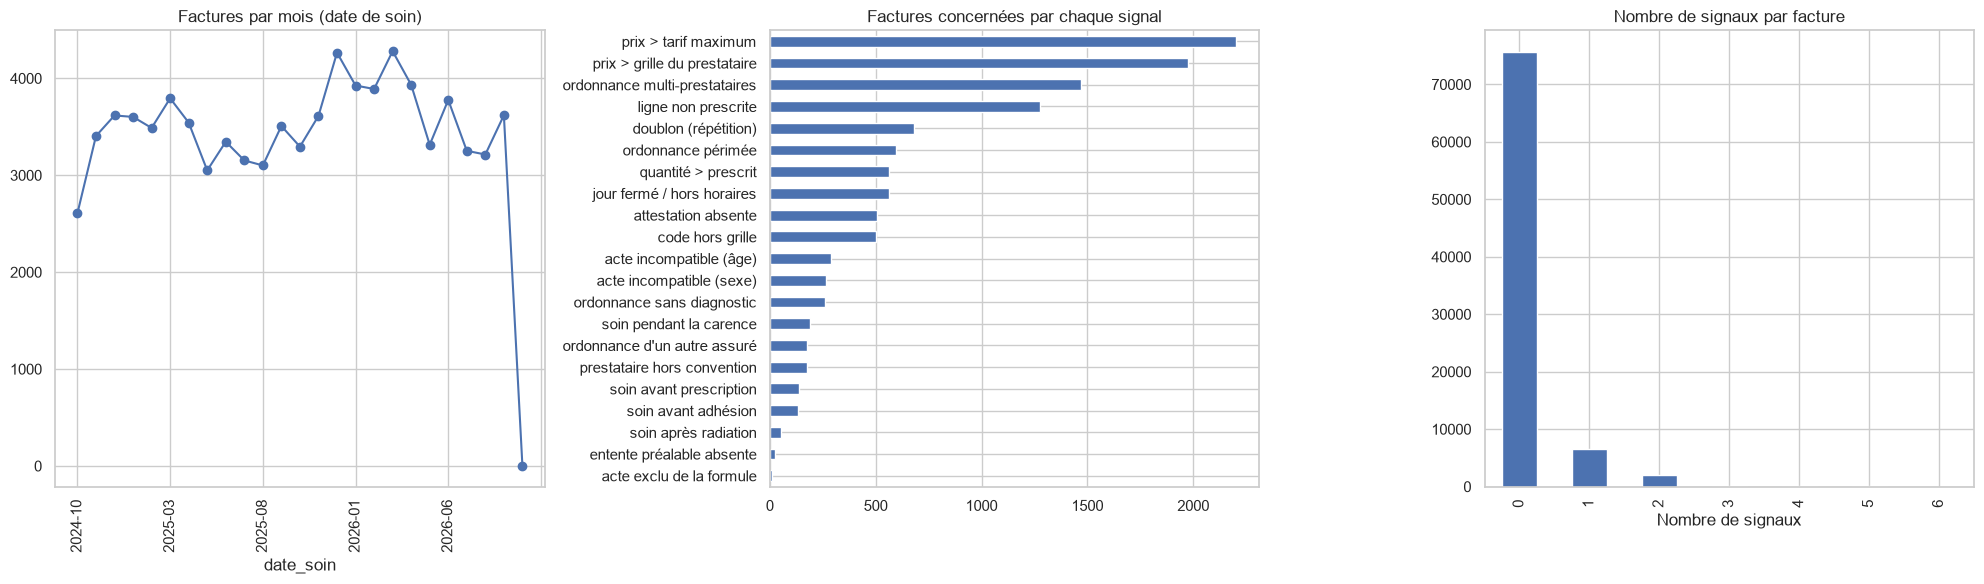

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Volume de factures par mois
par_mois = fact_full.groupby(fact_full.date_soin.dt.to_period("M")).size()
par_mois.index = par_mois.index.astype(str)
par_mois.plot(ax=axes[0], marker="o")
axes[0].set_title("Factures par mois (date de soin)")
axes[0].tick_params(axis="x", rotation=90)

# 2. Fréquence de chaque signal
signaux.sum().sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Factures concernées par chaque signal")

# 3. Nombre de signaux par facture
fact_full.nb_signaux.value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set_title("Nombre de signaux par facture")
axes[2].set_xlabel("Nombre de signaux")

sauver("exploration_signaux")

### 8.2 Montants et circuits de réception

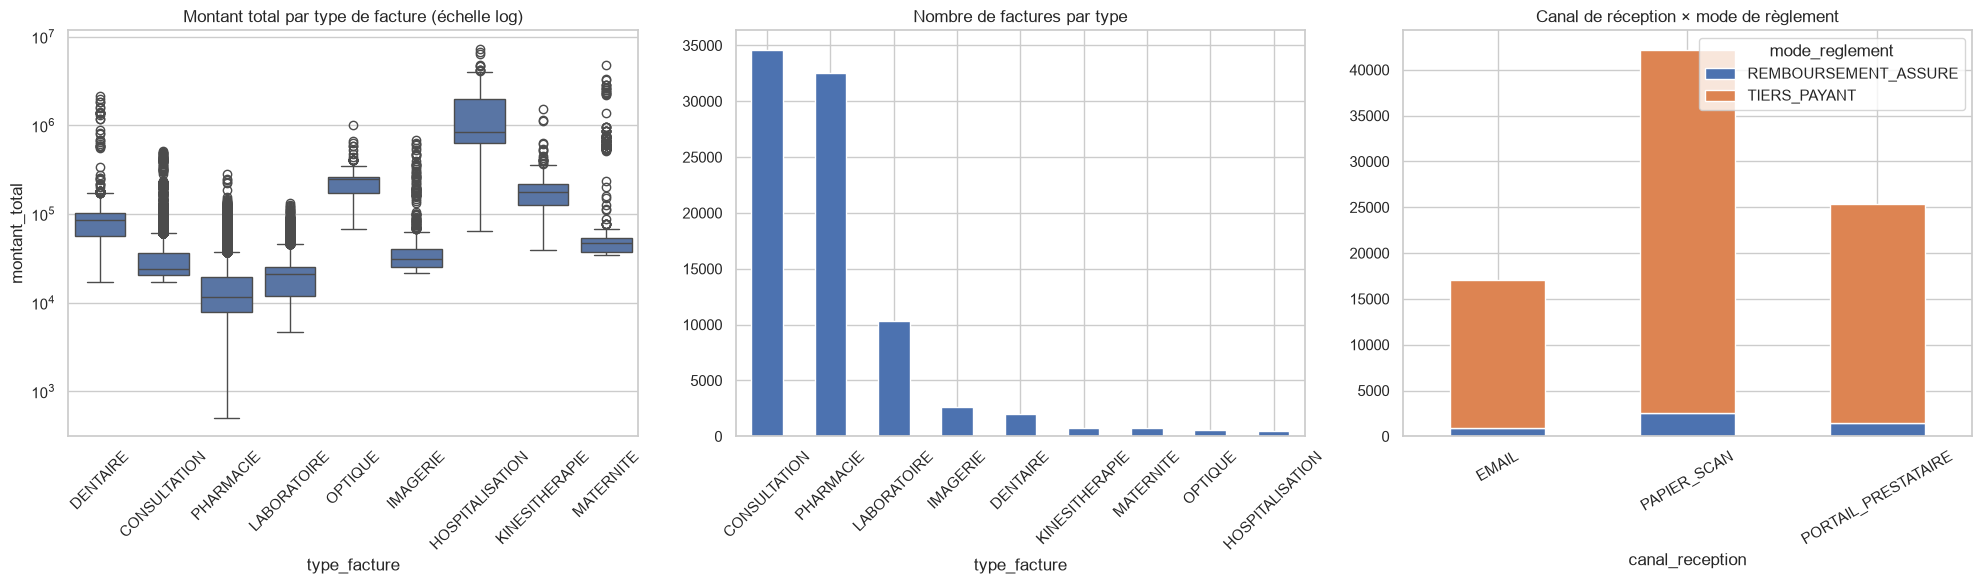

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.boxplot(data=fact_full, x="type_facture", y="montant_total", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Montant total par type de facture (échelle log)")
axes[0].tick_params(axis="x", rotation=45)

fact_full.type_facture.value_counts().plot.bar(ax=axes[1])
axes[1].set_title("Nombre de factures par type")
axes[1].tick_params(axis="x", rotation=45)

pd.crosstab(fact_full.canal_reception, fact_full.mode_reglement).plot.bar(ax=axes[2], stacked=True)
axes[2].set_title("Canal de réception × mode de règlement")
axes[2].tick_params(axis="x", rotation=30)

sauver("montants_et_circuits")

### 8.3 Quels signaux apparaissent ensemble ?

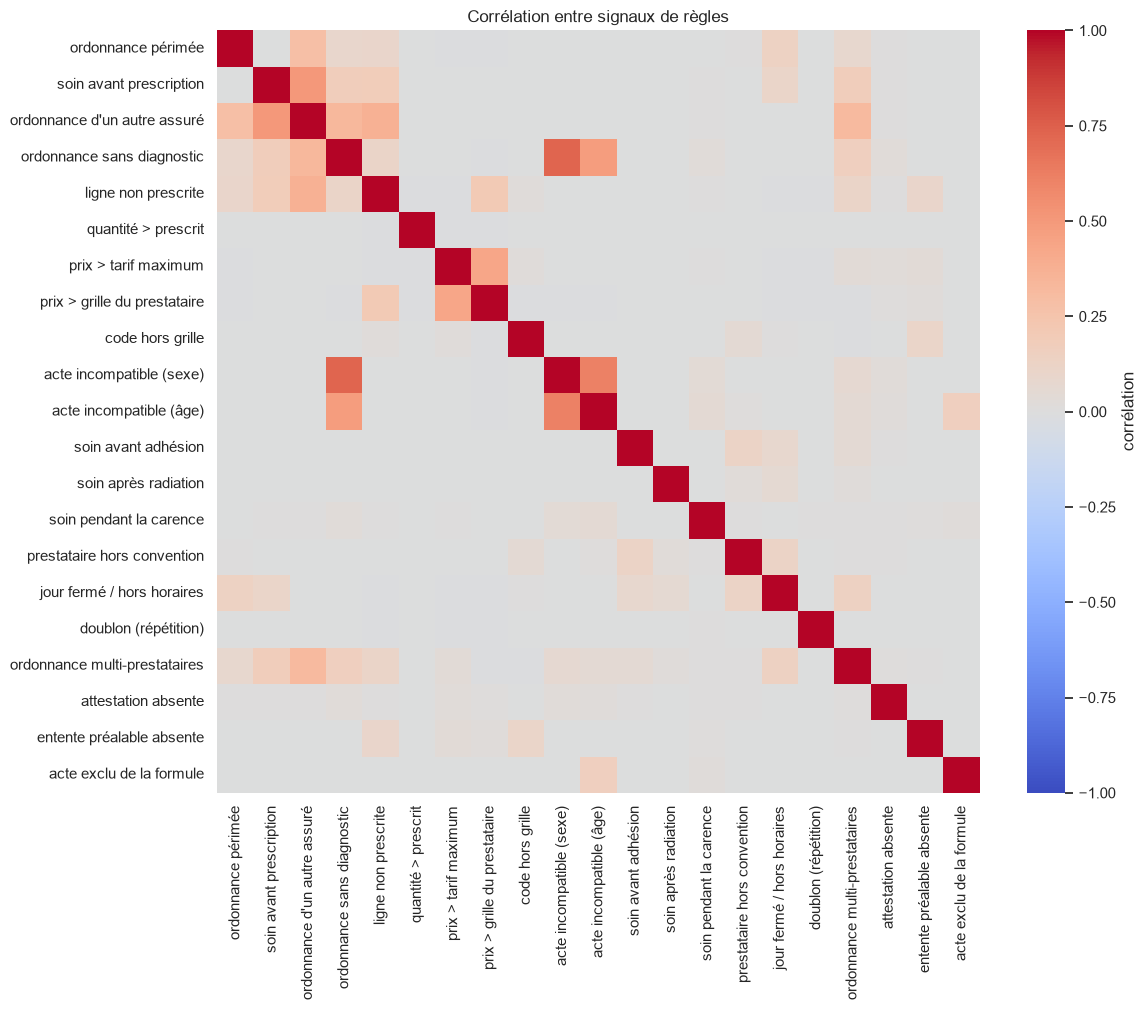

In [21]:
corr_signaux = signaux.astype(int).corr().fillna(0)

plt.figure(figsize=(12, 10))
sns.heatmap(corr_signaux, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "corrélation"})
plt.title("Corrélation entre signaux de règles")
sauver("correlation_signaux")

### 8.4 Où se concentrent les signaux : type de facture et prestataires

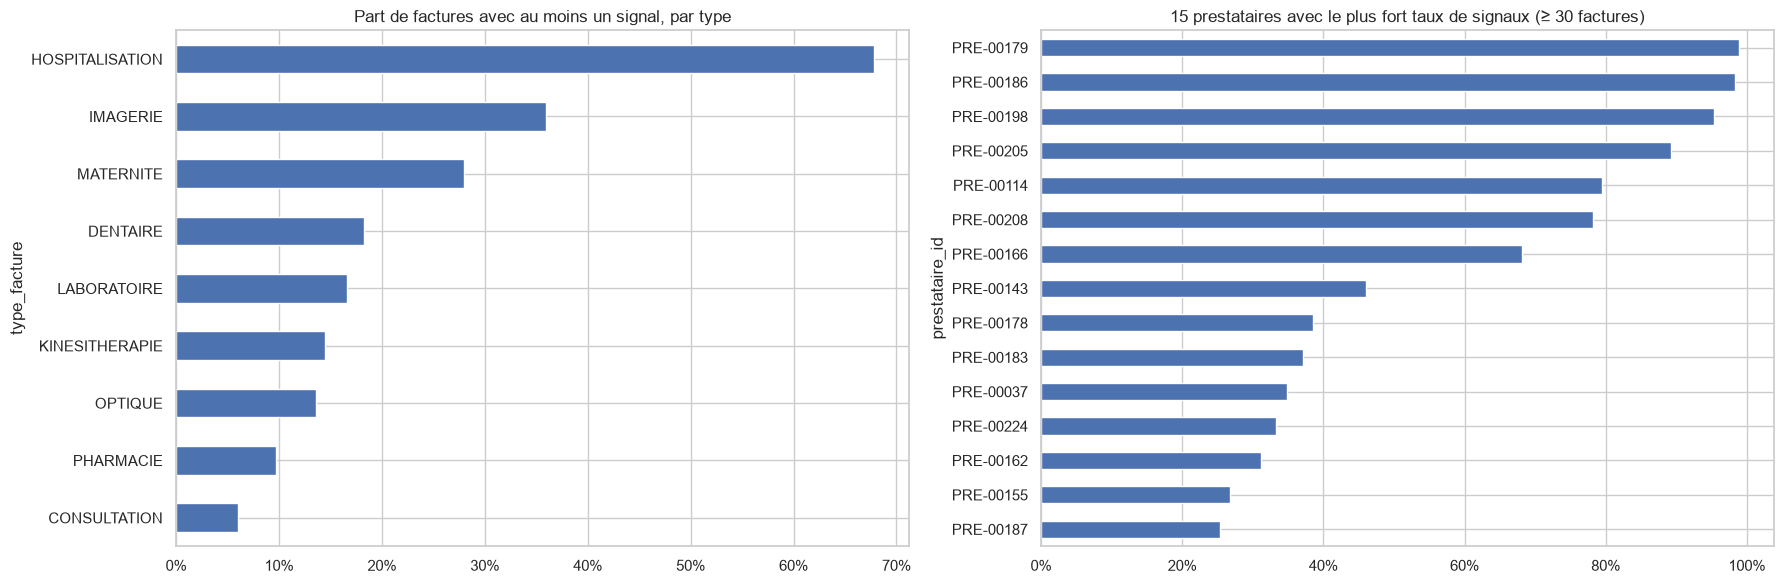

In [22]:
fact_full["a_signal"] = fact_full.nb_signaux > 0

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

(fact_full.groupby("type_facture").a_signal.mean().sort_values()
 .plot.barh(ax=axes[0]))
axes[0].set_title("Part de factures avec au moins un signal, par type")
axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

par_presta = fact_full.groupby("prestataire_id").agg(n=("facture_id", "size"),
                                                    taux=("a_signal", "mean"))
top = par_presta[par_presta.n >= 30].sort_values("taux").tail(15)
top.taux.plot.barh(ax=axes[1])
axes[1].set_title("15 prestataires avec le plus fort taux de signaux (≥ 30 factures)")
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

sauver("signaux_par_type_et_prestataire")

### 8.5 Prix, délais d'ordonnance et horaires

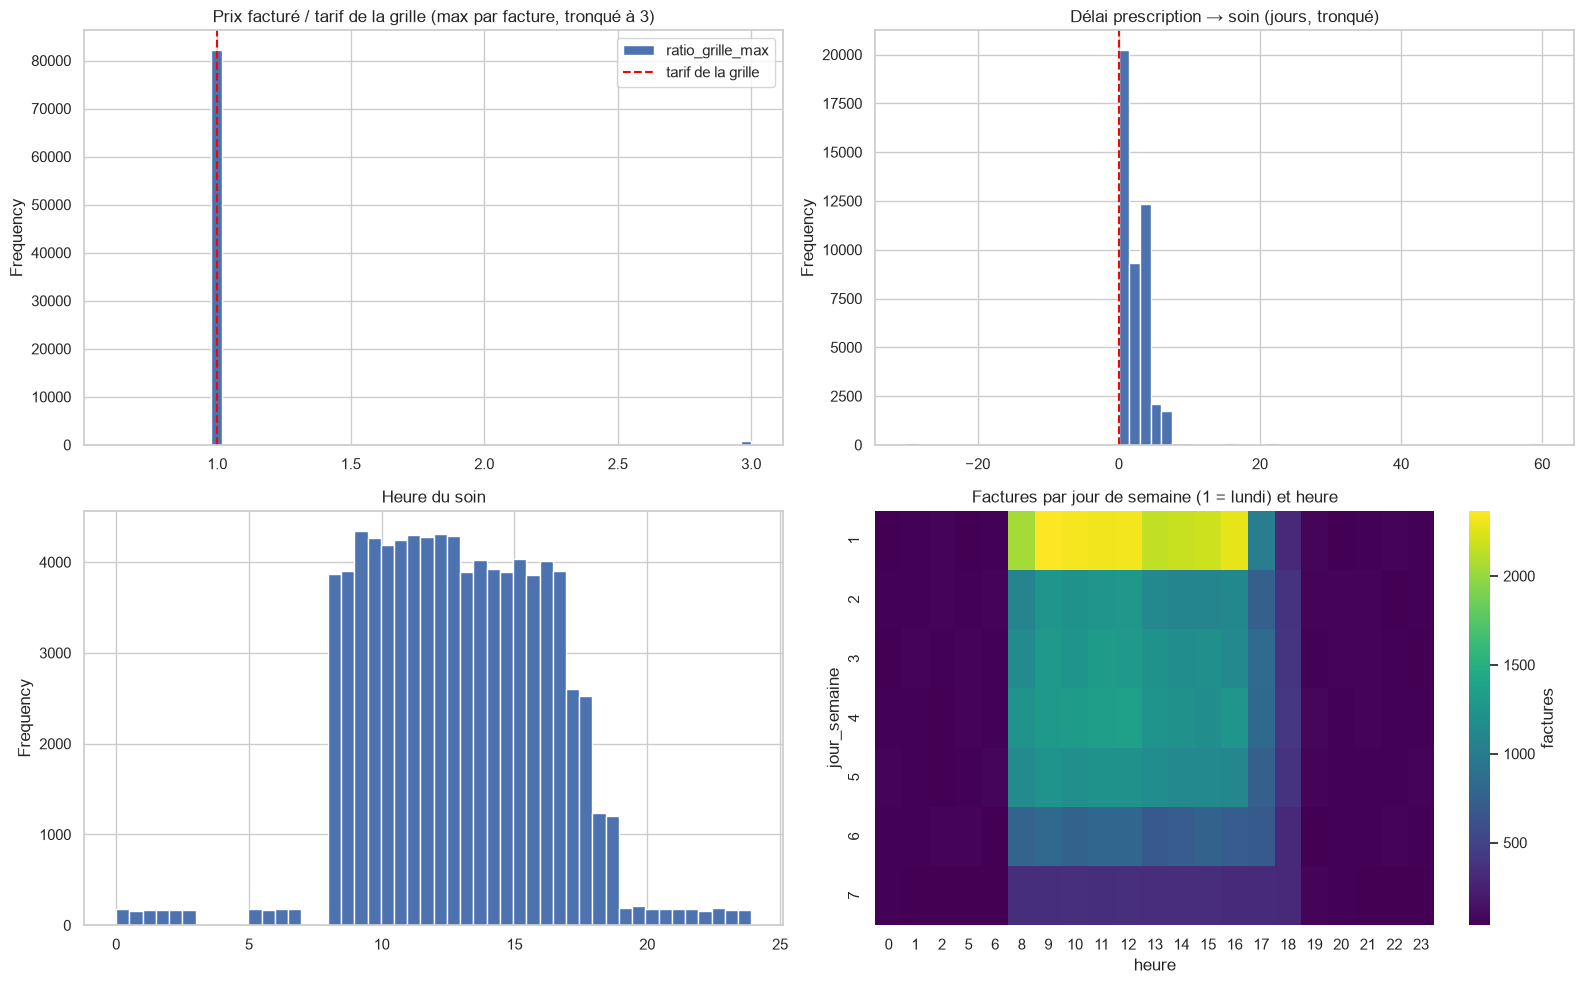

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

fact_full.ratio_grille_max.dropna().clip(0, 3).plot.hist(bins=60, ax=axes[0, 0])
axes[0, 0].axvline(1, color="red", linestyle="--", label="tarif de la grille")
axes[0, 0].set_title("Prix facturé / tarif de la grille (max par facture, tronqué à 3)")
axes[0, 0].legend()

fact_full.delai_ord_jours.dropna().clip(-30, 60).plot.hist(bins=60, ax=axes[0, 1])
axes[0, 1].axvline(0, color="red", linestyle="--")
axes[0, 1].set_title("Délai prescription → soin (jours, tronqué)")

fact_full.heure.plot.hist(bins=48, ax=axes[1, 0])
axes[1, 0].set_title("Heure du soin")

jh = pd.crosstab(fact_full.jour_semaine, fact_full.heure.astype(int))
sns.heatmap(jh, cmap="viridis", ax=axes[1, 1], cbar_kws={"label": "factures"})
axes[1, 1].set_title("Factures par jour de semaine (1 = lundi) et heure")

sauver("prix_delais_horaires")

### 8.6 Population des assurés (âge, sexe) et montants

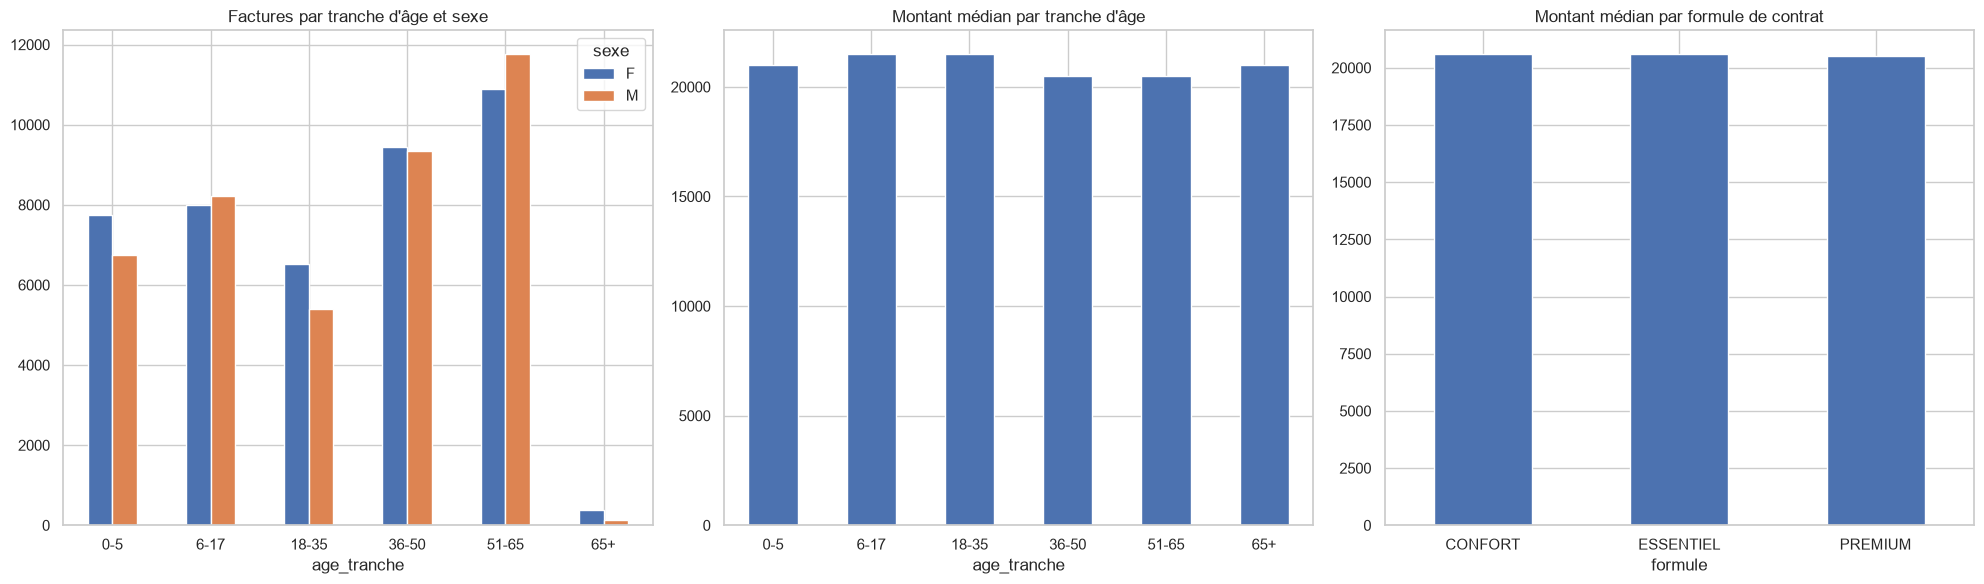

In [24]:
fact_full["age_tranche"] = pd.cut(fact_full.age_soin,
                                  bins=[-1, 5, 17, 35, 50, 65, 120],
                                  labels=["0-5", "6-17", "18-35", "36-50", "51-65", "65+"])

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

pd.crosstab(fact_full.age_tranche, fact_full.sexe).plot.bar(ax=axes[0])
axes[0].set_title("Factures par tranche d'âge et sexe")
axes[0].tick_params(axis="x", rotation=0)

fact_full.groupby("age_tranche", observed=True).montant_total.median().plot.bar(ax=axes[1])
axes[1].set_title("Montant médian par tranche d'âge")
axes[1].tick_params(axis="x", rotation=0)

fact_full.groupby("formule").montant_total.median().plot.bar(ax=axes[2])
axes[2].set_title("Montant médian par formule de contrat")
axes[2].tick_params(axis="x", rotation=0)

sauver("population_et_montants")

### 8.7 Risque de ré-identification (pour le rapport RGPD)



,% uniques (k=1),% rares (k<5)
schéma,,
sexe + année + ville,4.7,23.6
sexe + tranche d'âge + ville,0.1,0.5
sexe + tranche d'âge,0.0,0.1
sexe + année + ville + contrat,97.5,100.0
sexe + tranche + ville + contrat,85.5,100.0


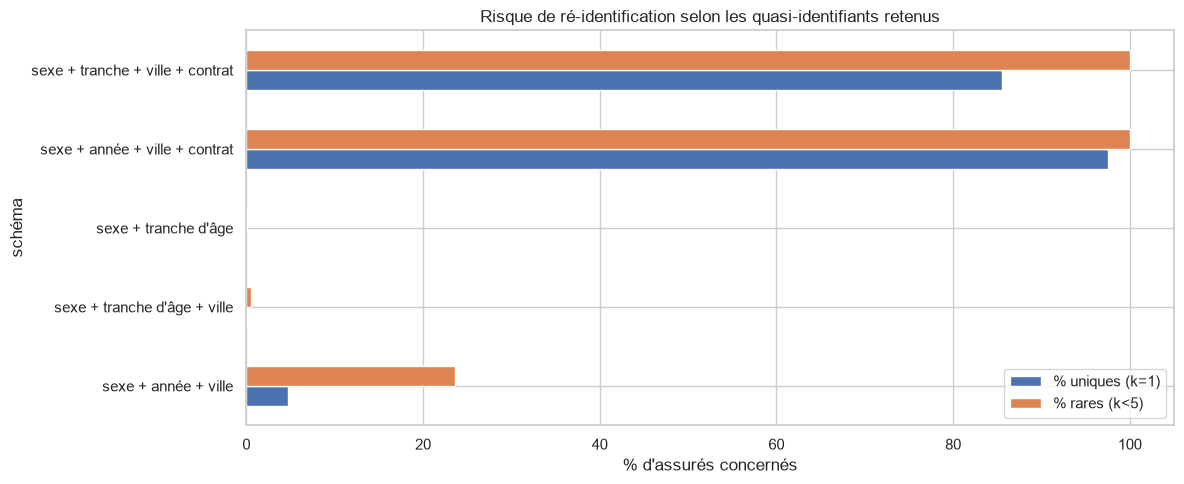

In [25]:
a = t["assures"].copy()
a["age_ref"] = 2025 - a.annee_naissance
a["tranche"] = pd.cut(a.age_ref, bins=[-1, 5, 17, 35, 50, 65, 120],
                      labels=["0-5", "6-17", "18-35", "36-50", "51-65", "65+"])

schemas = {
    "sexe + année + ville":             ["sexe", "annee_naissance", "ville"],
    "sexe + tranche d'âge + ville":     ["sexe", "tranche", "ville"],
    "sexe + tranche d'âge":             ["sexe", "tranche"],
    "sexe + année + ville + contrat":   ["sexe", "annee_naissance", "ville", "contrat_id"],
    "sexe + tranche + ville + contrat": ["sexe", "tranche", "ville", "contrat_id"],
}

lignes_k = []
for nom, cles_k in schemas.items():
    k = a.groupby(cles_k, observed=True)["assure_id"].transform("size")
    lignes_k.append({"schéma": nom,
                     "% uniques (k=1)": 100 * (k == 1).mean(),
                     "% rares (k<5)": 100 * (k < 5).mean()})
risque = pd.DataFrame(lignes_k).set_index("schéma")
display(risque.round(1))

risque.plot.barh(figsize=(12, 5))
plt.title("Risque de ré-identification selon les quasi-identifiants retenus")
plt.xlabel("% d'assurés concernés")
sauver("risque_reidentification")

## 9. Tableau de bord décisionnel 

>

Statuts des factures :
statut
PAYEE       79775
EN_COURS     2826
REJETEE      1992
Name: count, dtype: int64

Taux de rejet global : 2.4%


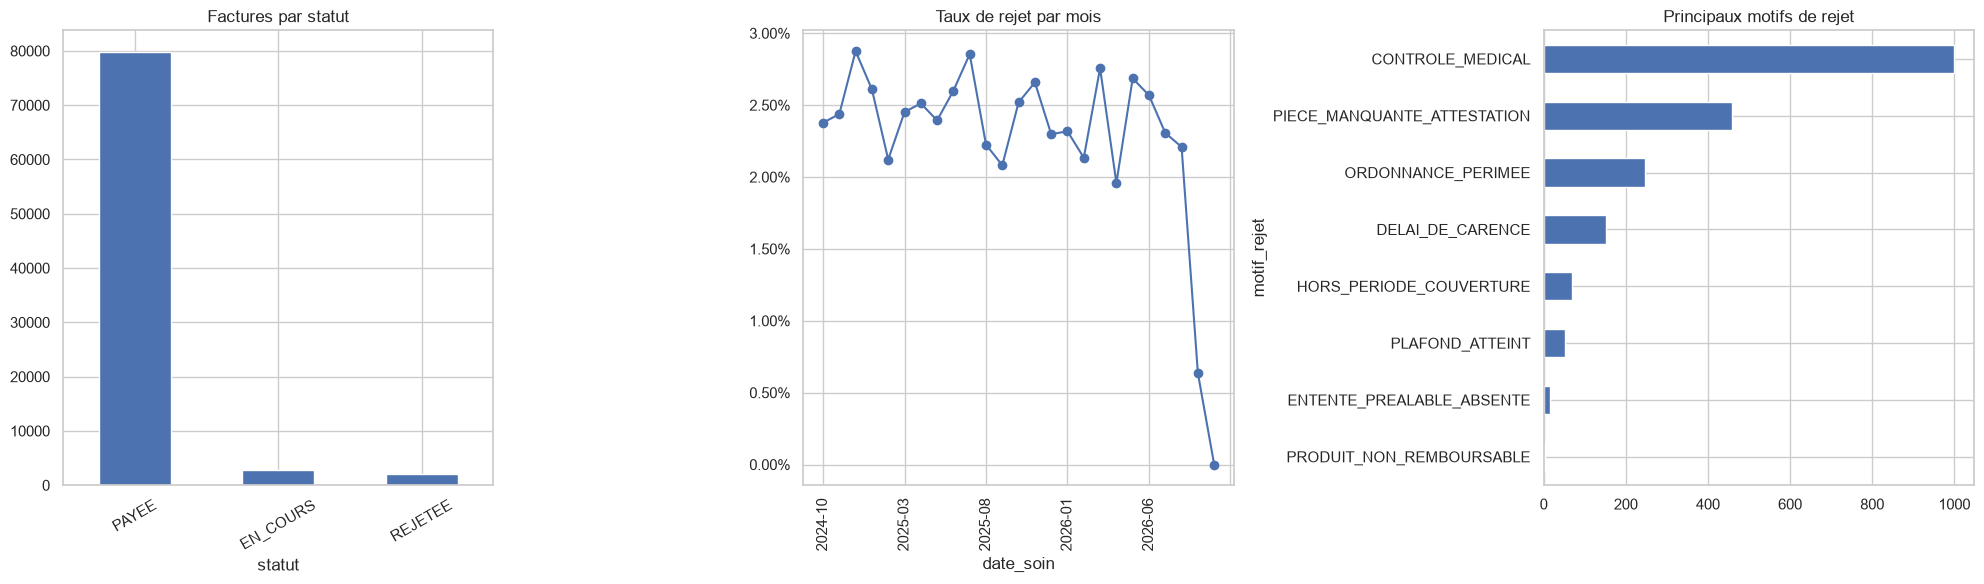

In [26]:
dec = decisions.merge(fact_full[["facture_id", "type_facture", "montant_total", "date_soin"]],
                      on="facture_id", how="left", validate="1:1")
dec["rejetee"] = dec.motif_rejet.notna()

print("Statuts des factures :")
print(dec.statut.value_counts())
print("\nTaux de rejet global : {:.1%}".format(dec.rejetee.mean()))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

dec.statut.value_counts().plot.bar(ax=axes[0])
axes[0].set_title("Factures par statut")
axes[0].tick_params(axis="x", rotation=30)

(dec.groupby(dec.date_soin.dt.to_period("M")).rejetee.mean()
 .rename(lambda p: str(p)).plot(ax=axes[1], marker="o"))
axes[1].set_title("Taux de rejet par mois")
axes[1].tick_params(axis="x", rotation=90)
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

dec.motif_rejet.value_counts().head(10).sort_values().plot.barh(ax=axes[2])
axes[2].set_title("Principaux motifs de rejet")

sauver("dashboard_decisions")

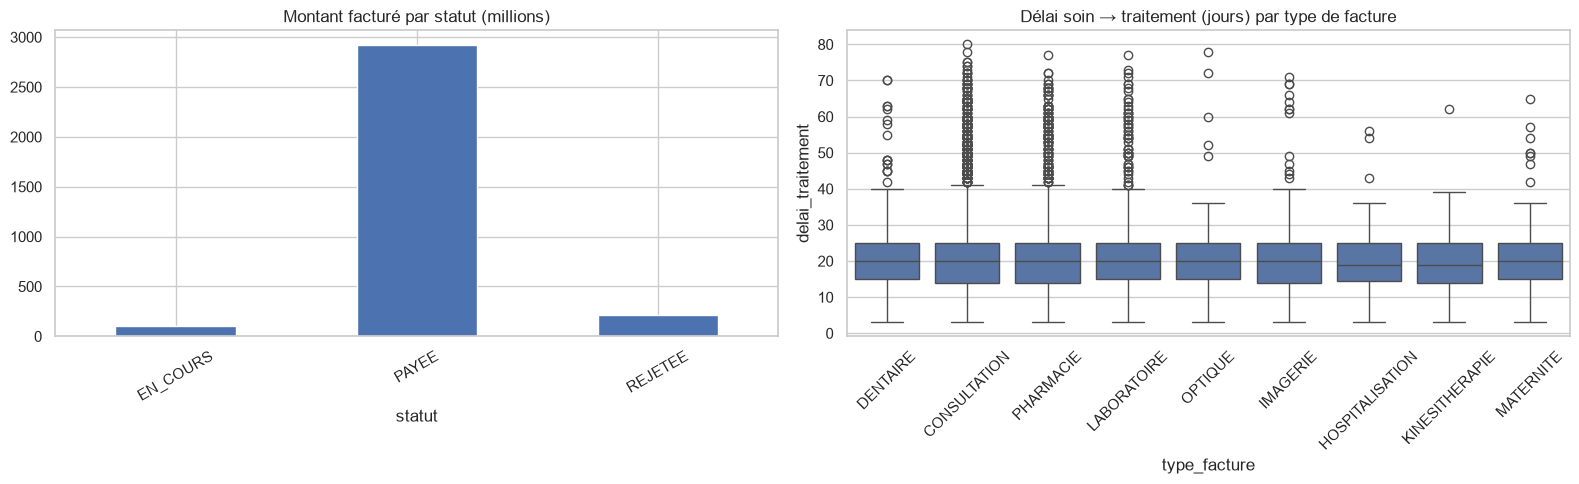

In [27]:
# Délai de traitement et montants par statut
dec["delai_traitement"] = (dec.date_traitement - dec.date_soin).dt.days

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dec.groupby("statut").montant_total.sum().div(1e6).plot.bar(ax=axes[0])
axes[0].set_title("Montant facturé par statut (millions)")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=dec, x="type_facture", y="delai_traitement", ax=axes[1])
axes[1].set_title("Délai soin → traitement (jours) par type de facture")
axes[1].tick_params(axis="x", rotation=45)

sauver("dashboard_delais_montants")

## 11. Matrice de features et contrôles RGPD



In [28]:
# Indicateurs de présence à la place des identifiants de documents
fact_full["a_ordonnance"] = fact_full.ordonnance_id.notna()
fact_full["a_attestation"] = fact_full.attestation_pec_id.notna()
fact_full["a_entente"] = fact_full.entente_prealable_id.notna()
fact_full["mois_soin"] = fact_full.date_soin.dt.month

# Clés conservées à part
CLES = ["facture_id", "assure_id", "prestataire_id", "contrat_id", "ordonnance_id", "date_soin"]
cles = fact_full[CLES].copy()

# Retrait des colonnes sensibles, des fuites, des identifiants et des dates brutes
IDENTIFIANTS = ["numero_facture", "prestataire_id", "contrat_id", "ordonnance_id",
                "ord_prescripteur_id", "attestation_pec_id", "entente_prealable_id",
                "heure_soin", "jours_ouverture"]
dates_brutes = list(fact_full.select_dtypes(include="datetime").columns)

a_retirer = COLONNES_SANTE + COLONNES_QUASI_IDENTIFIANTS + FUITE + IDENTIFIANTS + dates_brutes
X = fact_full.drop(columns=[c for c in a_retirer if c in fact_full.columns])
X = X.replace([np.inf, -np.inf], np.nan)

for c in X.select_dtypes(include="object").columns:
    X[c] = X[c].astype("category")

print("Colonnes retirées :", sorted(c for c in a_retirer if c in fact_full.columns))
print("X :", X.shape)
print(fact_full.head(3))

C:\Users\fanas\AppData\Local\Temp\ipykernel_50584\1957077137.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in X.select_dtypes(include="object").columns:


Colonnes retirées : ['annee_naissance', 'assure_id', 'assure_principal_id', 'attestation_pec_id', 'contrat_date_effet', 'contrat_date_fin', 'contrat_date_police', 'contrat_id', 'date_adhesion', 'date_conventionnement', 'date_facture', 'date_fin_convention', 'date_prescription', 'date_radiation', 'date_reception', 'date_soin', 'diagnostic', 'entente_prealable_id', 'heure_soin', 'jours_ouverture', 'numero_facture', 'ord_assure_id', 'ord_prescripteur_id', 'ordonnance_id', 'prestataire_id', 'ville_assure']
X : (84593, 67)
     facture_id     numero_facture prestataire_id       assure_id  contrat_id  \
0  FAC-00000001  CDD214/2024/00001      PRE-00214  ASS-9CAA1484E0  CTR-000001   
1  FAC-00000002  DRT086/2024/00001      PRE-00086  ASS-9CAA1484E0  CTR-000001   
2  FAC-00000003  PLM057/2024/00001      PRE-00057  ASS-9CAA1484E0  CTR-000001   

  ordonnance_id  type_facture  date_soin heure_soin date_facture  ...  \
0           NaN      DENTAIRE 2024-11-11      09:45   2024-11-14  ...   
1    

In [29]:
verifier_sans_pii(X)
verifier_features_ml(X)
assert not set(FUITE) & set(X.columns), "Colonne de fuite présente dans X"
assert X.facture_id.is_unique, "facture_id doit être unique"
print("OK : aucune identité, donnée de santé brute, quasi-identifiant ni fuite dans X")

X.to_parquet(PROCESSED / "features.parquet", index=False)
cles.to_parquet(PROCESSED / "cles.parquet", index=False)
print("Exporté :", PROCESSED / "features.parquet", X.shape)
print("Exporté :", PROCESSED / "cles.parquet", cles.shape)

OK : aucune identité, donnée de santé brute, quasi-identifiant ni fuite dans X
Exporté : ..\data\processed\features.parquet (84593, 67)
Exporté : ..\data\processed\cles.parquet (84593, 6)
